In [4]:
import h5py
import pickle

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
filename = 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5'
with h5py.File(root + filename, 'r') as f:
    qn_matrix = f['data/qn_matrix'][:]
    gene_names = f['meta/genes/all_gene_names'][:]
    biosample_names = f['meta/biosamples/threshold_biosample_names'][:]

biosample_names = [x.decode('UTF-8') for x in biosample_names]
gene_names_decoded = [x.decode('UTF-8') for x in gene_names]

In [45]:
def get_gene_names(filename, geneset_name):
    gene_names = []
    with open(filename) as file:
        for line in file:
            line = line.strip().split('\t')
            if line[0] == geneset_name:
                gene_names = line[2:]
                break
    return gene_names

# Input file name
root = "/home/lwu/ARCHS4/Tests/Check If Biosample Categorys Align With Genesets/"
filename = 'h.c1.c2.all.v7.5.1.symbols.gmt'

# Geneset name
geneset_name1 = 'THUM_MIR21_TARGETS_HEART_DISEASE_DN'
geneset_name2 = "WP_HEART_DEVELOPMENT"
geneset_name3 = 'PETRETTO_HEART_MASS_QTL_CIS_DN'

# Call the function to get the gene names
gene_names1 = get_gene_names(root + filename, geneset_name1)
gene_names2 = get_gene_names(root + filename, geneset_name2)
gene_names3 = get_gene_names(root + filename, geneset_name3)

# Print the gene names
print("THUM_MIR21_TARGETS_HEART_DISEASE_DN:", len(gene_names1))
print("WP_HEART_DEVELOPMENT:", len(gene_names2))
print("PETRETTO_HEART_MASS_QTL_CIS_DN:", len(gene_names3))

THUM_MIR21_TARGETS_HEART_DISEASE_DN: 9
WP_HEART_DEVELOPMENT: 46
PETRETTO_HEART_MASS_QTL_CIS_DN: 26


In [46]:
def get_gene_indexes(gene_names, genes_names_all):
    gene_indexes = []
    for gene in gene_names:
        try:
            index = genes_names_all.index(gene)
            gene_indexes.append(index)
        except ValueError:
            print("Not Found: ", gene)
    return gene_indexes

# Call the function to get the gene indexes
gene_indexes1 = get_gene_indexes(gene_names1, gene_names_decoded)
gene_indexes2 = get_gene_indexes(gene_names2, gene_names_decoded)
gene_indexes3 = get_gene_indexes(gene_names3, gene_names_decoded)

# Print the gene indexes
print(gene_indexes1)
print(gene_indexes2)
print(gene_indexes3)

Not Found:  SMAD1
[1291, 41331, 50759, 1366, 6759, 4443, 39020, 210, 3798]
[28292, 2268, 30295, 43099, 28293, 55742, 55744, 38788, 55743, 38789, 26407, 38931, 26596, 2328, 2330, 26597, 2335, 5161, 52950, 28492, 2345, 50156, 52066, 2350, 51027, 35297, 26619, 34881, 27092, 27090, 26592, 34584, 30312, 50868, 25459, 52952, 28493, 26373, 39070, 38792, 35113, 38793, 52958, 52944, 41678]
[30299, 28597, 55065, 4571, 1364, 38751, 38066, 2925, 3785, 28628, 52171, 28601, 38599, 49943, 27297, 7125, 31426, 56553, 1411, 43185, 29333, 50231, 30264, 52044, 6973, 43883]


In [52]:
if "SMAD1" in gene_names2:
    gene_names2.remove("SMAD1")

---

---

In [29]:
# extract the data based on the indices of the genes to extract
extracted_matrix = qn_matrix[gene_indexes1, :] 
print(len(extracted_matrix))
print(extracted_matrix.shape)
# convert the extracted data into a matrix with sample names as the columns
#extracted_matrix = [{sample_names[j]: extracted_matrix[i][j] for j in range(len(sample_names))

9
(9, 87875)


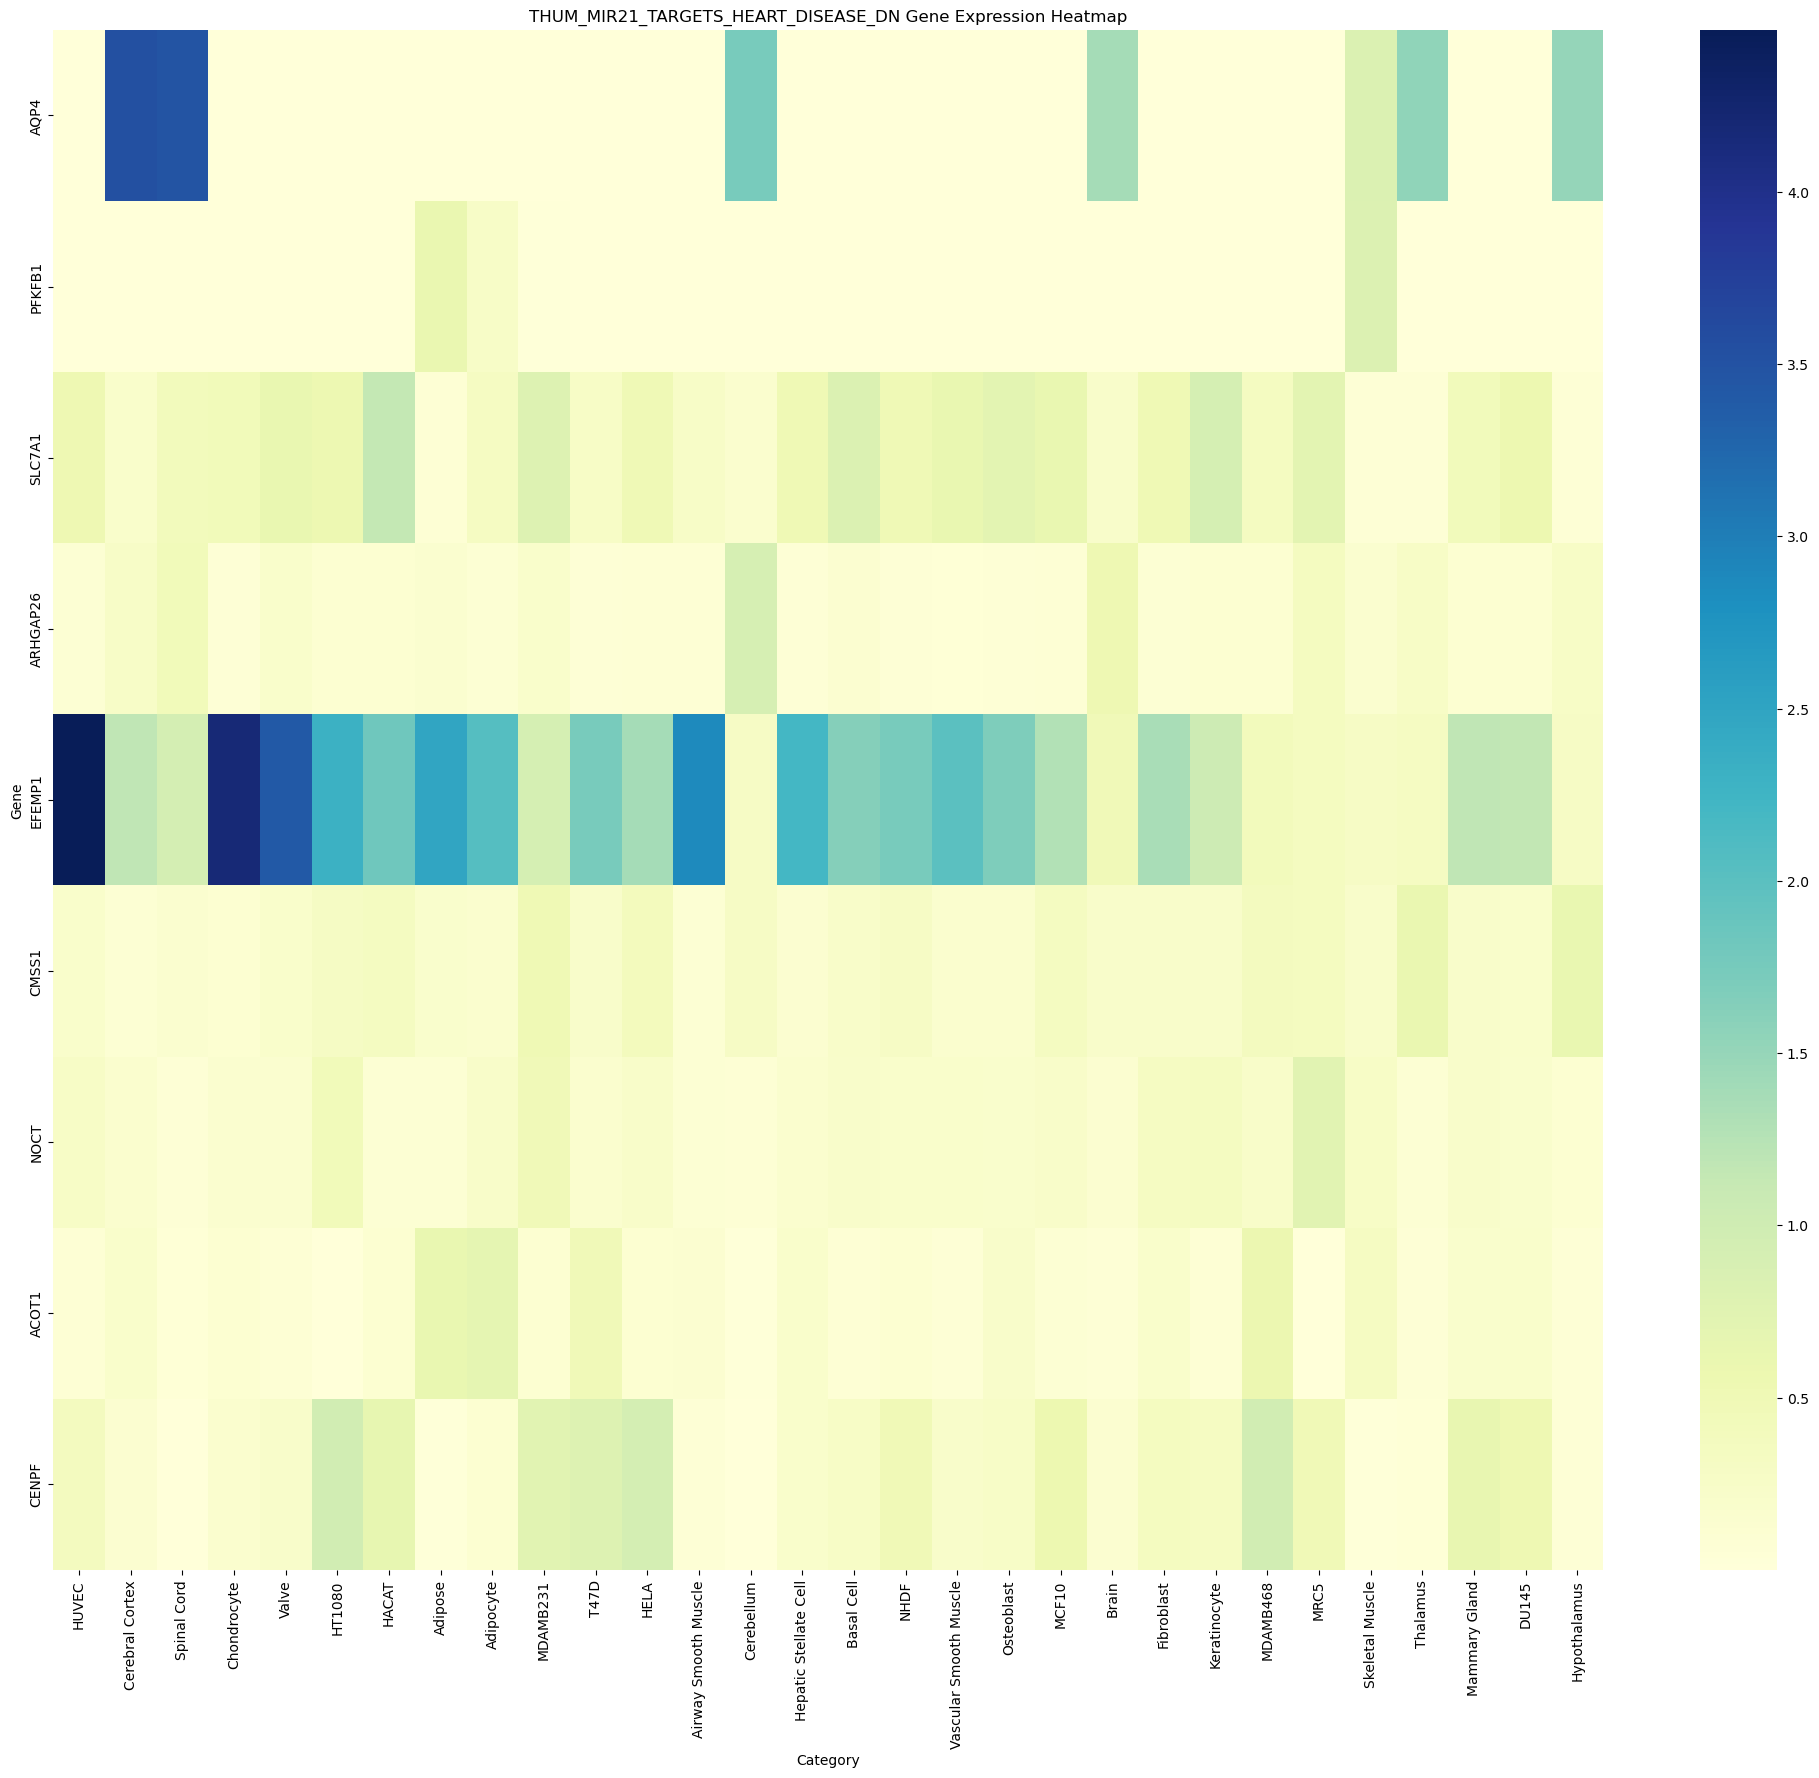

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Sample data
#data = [[2, 3, 4, 5, 6, 7], [8, 9, 10, 11, 12, 13], [14, 15, 16, 17, 18, 19]]
extracted_matrix = qn_matrix[gene_indexes1, :] 

# Category names
categories = [  # Cardiovascular
    "Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle",
    "HUVEC",  # Endothelial

    # Connective Tissue
    "Adipose", "Adipocyte",
    "Myofibroblast", "Osteoblast", "Stromal Cell", "MG63", "K562",  # Bone
    "Bone Marrow",
    "Chondrocyte",
    "HT1080", "NHDF",  # Connective

    # Digestive
    "Esophagus",
    "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", "Small Intestine",
    "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell", "HEPG2",  # Liver
    "Alpha Cell", "Beta Cell", "Pancreatic Islet", "PANC1",  # Pancreas
    "Gastric Epithelial Cell",
    "HCT116", "HT29", "RKO",  # Connective, Colon

    # Immune
    "Granulocyte", "Neutrophil",
    "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", "Tlymphocyte",
    "JURKAT", "MT4", "NALM6", "REH", "RPMI8226",  # Lymphoid
    "Alveolar", "Dendritic", "Kupffer", "Macrophage", "Macroglia",
    "THP1", "U937",  # Myeloid
    "JEG3",  # Placenta
    "Spleen",
    "Thymus", "Thymocyte",

    # Integumentary
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC",

    # Muscular
    "Skeletal Muscle", "Myoblast",
    "Airway Smooth Muscle",  # "Myofibroblast", [Repeat]
    "Respiratory Smooth Muscle", "Vascular Smooth Muscle",
    "LHCNM2",  # Muscle

    # Nervous
    "Astrocyte", "Cerebellum", "Cerebral Cortex", "Hypothalamus", "Medula",
    "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", "Thalamus",
    "Retina",
    "Motor Neuron", "Sensory Neuron",
    "Brain",  # Example in the ARCHS4 Website [1]
    "DAOY", "IMR32", "SKNSH",  # Brain

    # Respiratory
    # "Alveolar", [Repeat]
    "Lung", "Lung Epithelial",
    "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE",  # Lung
    "Trachea",

    # Urogenital
    "Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D",
    "HELA",  # Cervix
    "Kidney", "Podocyte", "Renal Cortex",
    "293F", "FLPIN TREX 293", "HEK293",  # Kidney
    "C42", "DU145", "LNCAP", "PC3",  # Prostate

    "Ovary", "Granulosa", "Oocyte",
    "ES2", "SKOV3",  # Ovary
    "Testis",
    "GSE81547",  # Example in the ARCHS4 GitHub
    "GSE30017", "GSM2679484"]  # Examples in the ARCHS4 Website [2]

# Organize samples into categories
# Create a dictionary to store the categories and their corresponding sample indexes
category_dict = {}

# Loop through the category names
for category in categories:
  # Create a list to store the sample indexes for the current category
  sample_indexes = []
  # Loop through the sample names
  for index, sample in enumerate(biosample_names):
    # Check if the current sample name contains the category keyword
    if category.replace(" ", "").lower() in sample.replace(" ", "").lower():
      # Add the sample index to the list
      sample_indexes.append(index)
  # Add the sample indexes to the dictionary with the category name as the key
  category_dict[category] = sample_indexes

# Create a dataframe from the sample data
df = pd.DataFrame(extracted_matrix, columns=biosample_names)

# Create a new dataframe with the sum of gene expression values for each category
category_df = pd.DataFrame(index=df.index)

# Create an empty list to store the category dataframes
category_df_list = []

# Loop through the categories
for category, sample_indexes in category_dict.items():
  # Sum the gene expression values for the samples in the current category
  category_mean = df[df.columns[sample_indexes]].mean(axis=1)
  # Create a dataframe from the sum of values
  category_df = pd.DataFrame({category: category_mean})
  # Add the dataframe to the list
  category_df_list.append(category_df)

# Concatenate the dataframes in the list along columns (axis=1)
category_df = pd.concat(category_df_list, axis=1)


# Sort the columns of the new dataframe based on the sum of each column
category_df = category_df.loc[:, category_df.sum().sort_values(ascending=False).index]


# Set the index of the dataframe to the row names
category_df.index = gene_names1

# Create a heatmap
plt.figure(figsize=(25, 20))
sns.heatmap(category_df.iloc[:, :30], cmap="YlGnBu")
plt.title("THUM_MIR21_TARGETS_HEART_DISEASE_DN Gene Expression Heatmap")
plt.xlabel("Category")
plt.ylabel("Gene")
plt.show()
 

In [37]:
category_df

,HUVEC,Cerebral Cortex,Spinal Cord,Chondrocyte,Valve,HT1080,HACAT,Adipose,Adipocyte,MDAMB231,...,GSE30017,NCIH460,FLPIN TREX 293,Macroglia,Respiratory Smooth Muscle,LHCNM2,Medula,Colonic Muscosa,SKNSH,GSM2679484
AQP4,0.000886,3.541482,3.490894,0.000721,0.003420,0.000430,0.000816,0.008451,0.005640,0.002586,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PFKFB1,0.006000,0.009157,0.001996,0.008266,0.004495,0.002604,0.017013,0.609623,0.247692,0.028592,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SLC7A1,0.535410,0.202069,0.413127,0.438238,0.626537,0.547246,1.143012,0.076598,0.321012,0.792723,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARHGAP26,0.104026,0.250210,0.451364,0.054407,0.206823,0.116613,0.108656,0.140531,0.091580,0.194828,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EFEMP1,4.469787,1.173499,0.937370,4.189235,3.407606,2.308722,1.826288,2.484565,2.055671,0.920013,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CMSS1,0.209660,0.097605,0.146447,0.120176,0.203747,0.297236,0.347639,0.177124,0.173428,0.509098,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NOCT,0.263603,0.161383,0.060398,0.153956,0.140095,0.452261,0.090646,0.104632,0.244661,0.462410,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACOT1,0.081444,0.208101,0.039943,0.121010,0.073692,0.010721,0.113310,0.612466,0.696413,0.109147,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CENPF,0.372754,0.128895,0.012375,0.159496,0.211072,0.965704,0.663656,0.018710,0.110092,0.748499,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
category_df

,Kidney,HELA,Liver,Breast,Skin,Bone Marrow,Brain,HEK293,Lung,Fibroblast,...,NCIH460,Respiratory Smooth Muscle,LHCNM2,Colonic Muscosa,Medula,SKNSH,Cardiac Muscle Fiber,GSE81547,GSE30017,GSM2679484
AQP4,2.750338e+04,1.323197e+03,28650.955078,2.038747e+04,2.957631e+03,5704.437012,996793.250000,7012.542969,125807.132812,981.173279,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PFKFB1,4.005254e+04,3.790478e+03,695434.875000,9.097212e+04,1.008784e+04,10625.107422,2696.209717,7602.334961,6588.479004,2311.891357,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SLC7A1,5.279249e+05,4.702701e+05,177760.625000,5.902635e+05,4.631655e+05,279291.250000,152658.015625,497732.718750,145477.156250,211530.906250,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ARHGAP26,2.041196e+05,7.358683e+04,203620.390625,1.399802e+05,1.008567e+05,402596.875000,380559.718750,48228.488281,97428.007812,36578.902344,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EFEMP1,2.857753e+05,1.300201e+06,502850.468750,1.012382e+06,1.122572e+06,95282.648438,330801.750000,53773.210938,486410.218750,561948.500000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CMSS1,1.589867e+06,3.634618e+05,224004.890625,2.973189e+05,1.836764e+05,429277.843750,156910.437500,313396.750000,114106.031250,87363.242188,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
NOCT,3.606667e+05,2.260239e+05,423162.093750,2.291856e+05,1.438518e+05,466814.812500,98963.507812,188237.531250,92660.804688,134974.671875,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ACOT1,8.652102e+05,1.000195e+05,755125.750000,2.369179e+05,1.917630e+05,113018.000000,49287.449219,79083.250000,75680.703125,83775.531250,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CENPF,1.053582e+06,8.753959e+05,112561.875000,4.926785e+05,1.583848e+05,481885.656250,90250.843750,563260.125000,126438.210938,146601.328125,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


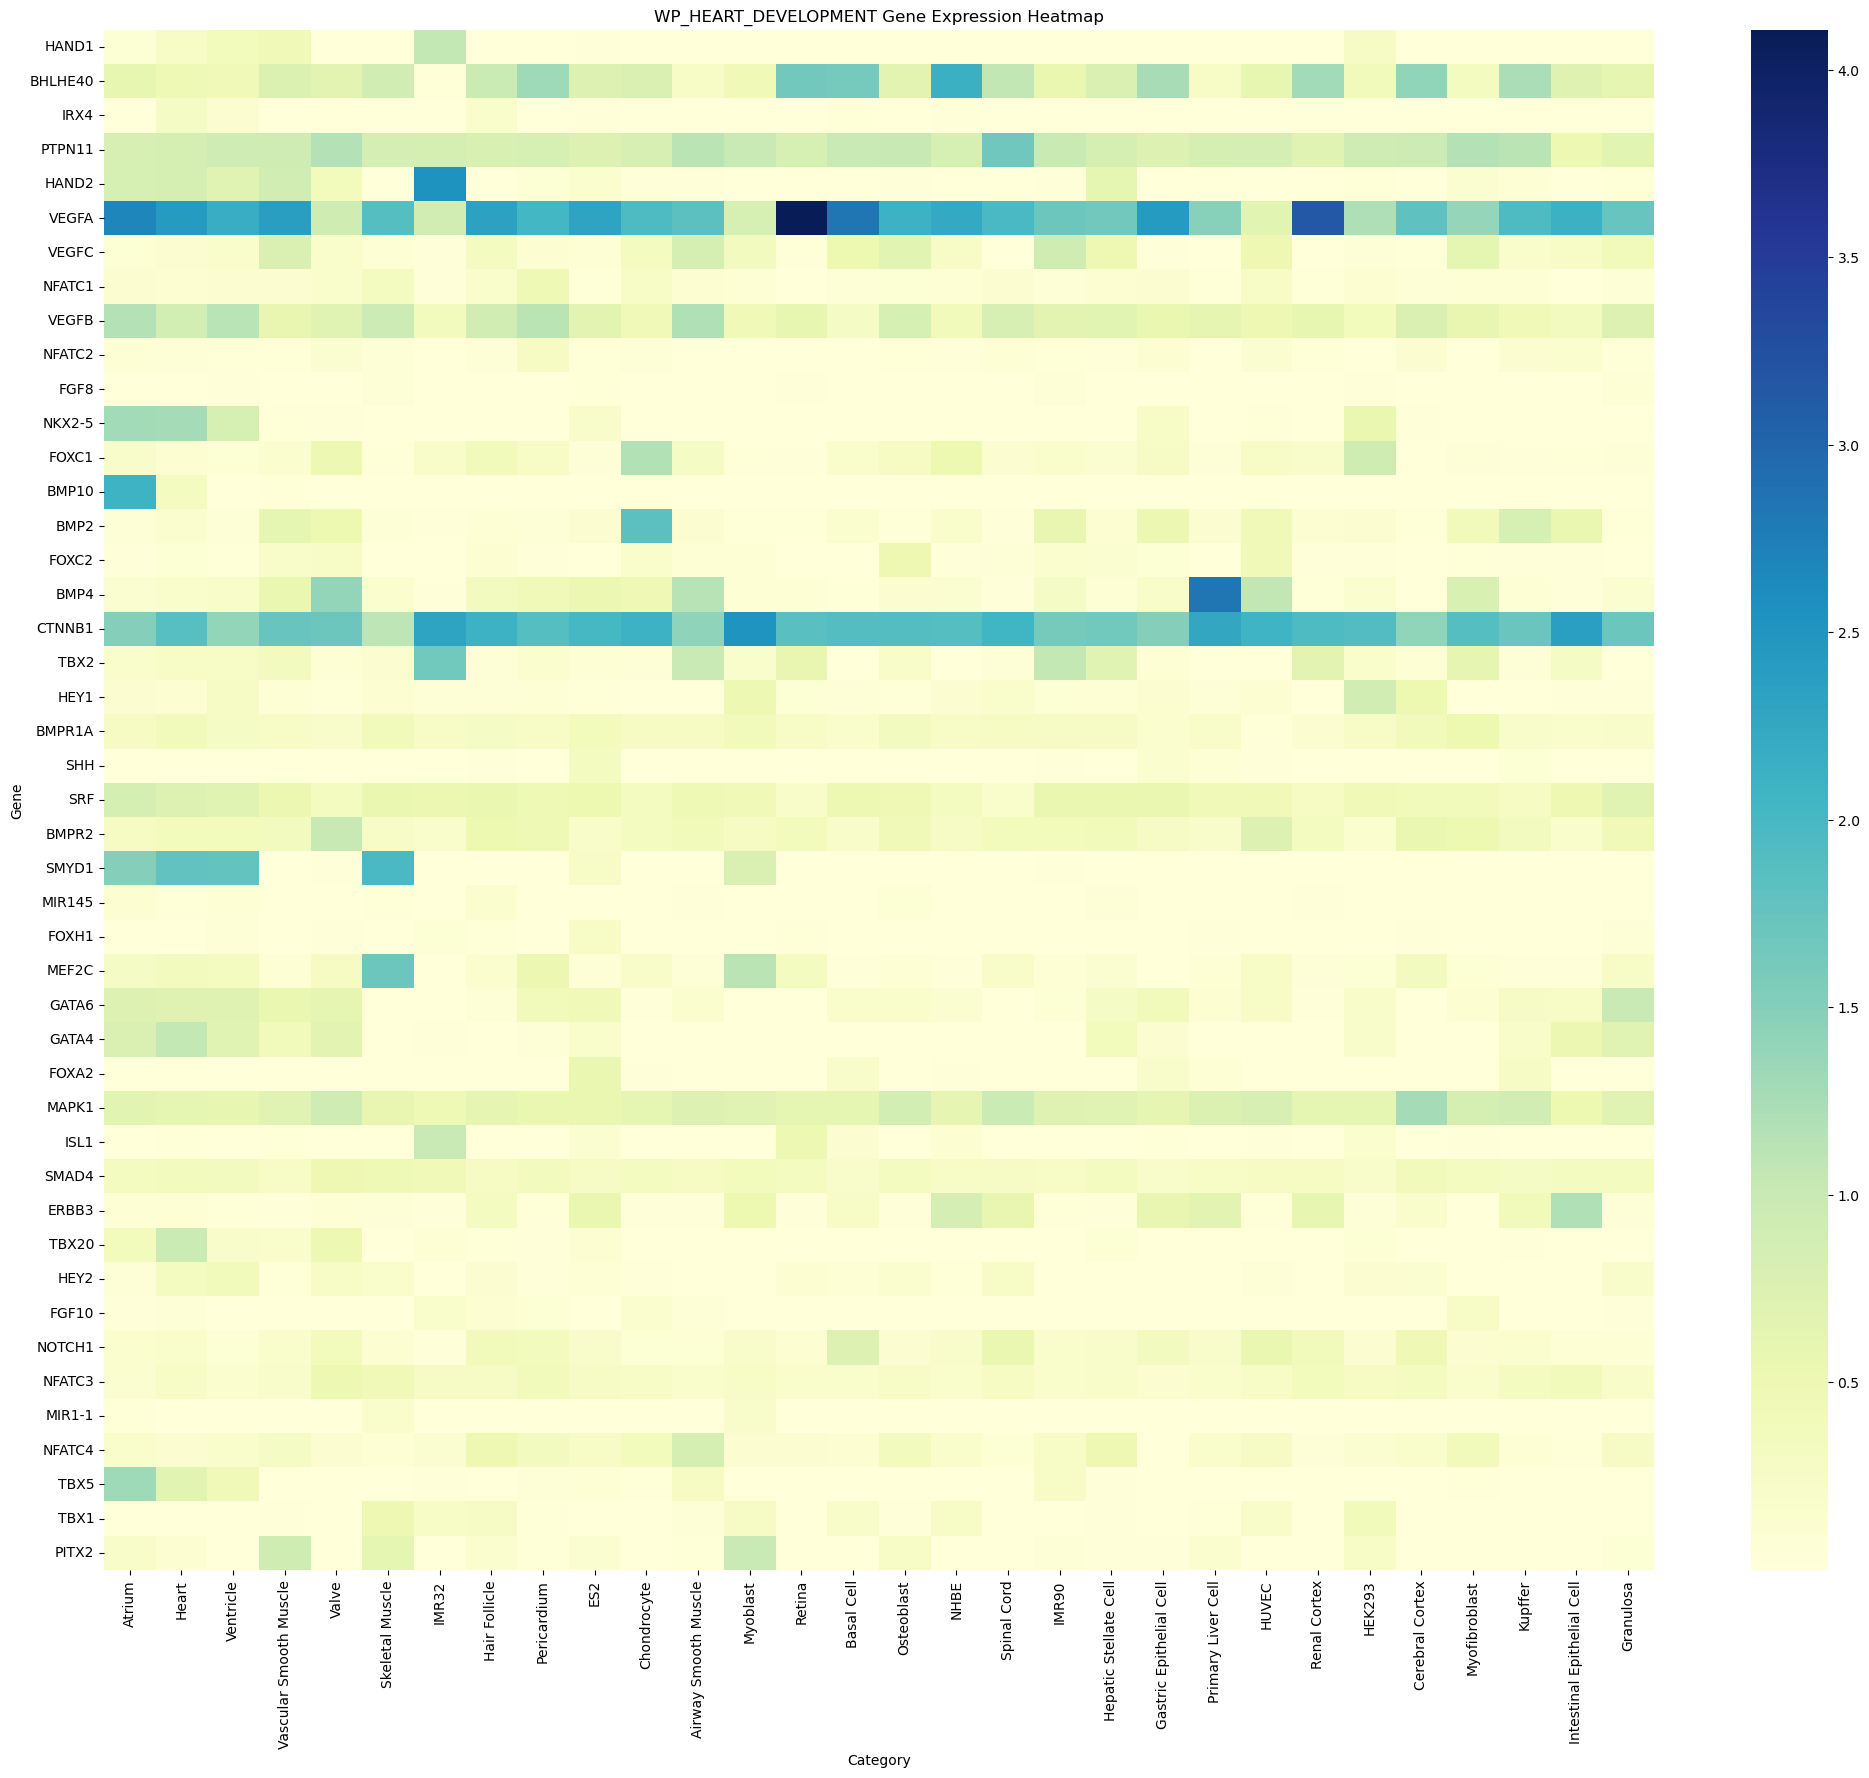

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Sample data
#data = [[2, 3, 4, 5, 6, 7], [8, 9, 10, 11, 12, 13], [14, 15, 16, 17, 18, 19]]
extracted_matrix = qn_matrix[gene_indexes2, :] 

# Category names
categories = [  # Cardiovascular
    "Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle",
    "HUVEC",  # Endothelial

    # Connective Tissue
    "Adipose", "Adipocyte",
    "Myofibroblast", "Osteoblast", "Stromal Cell", "MG63", "K562",  # Bone
    "Bone Marrow",
    "Chondrocyte",
    "HT1080", "NHDF",  # Connective

    # Digestive
    "Esophagus",
    "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", "Small Intestine",
    "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell", "HEPG2",  # Liver
    "Alpha Cell", "Beta Cell", "Pancreatic Islet", "PANC1",  # Pancreas
    "Gastric Epithelial Cell",
    "HCT116", "HT29", "RKO",  # Connective, Colon

    # Immune
    "Granulocyte", "Neutrophil",
    "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", "Tlymphocyte",
    "JURKAT", "MT4", "NALM6", "REH", "RPMI8226",  # Lymphoid
    "Alveolar", "Dendritic", "Kupffer", "Macrophage", "Macroglia",
    "THP1", "U937",  # Myeloid
    "JEG3",  # Placenta
    "Spleen",
    "Thymus", "Thymocyte",

    # Integumentary
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC",

    # Muscular
    "Skeletal Muscle", "Myoblast",
    "Airway Smooth Muscle",  # "Myofibroblast", [Repeat]
    "Respiratory Smooth Muscle", "Vascular Smooth Muscle",
    "LHCNM2",  # Muscle

    # Nervous
    "Astrocyte", "Cerebellum", "Cerebral Cortex", "Hypothalamus", "Medula",
    "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", "Thalamus",
    "Retina",
    "Motor Neuron", "Sensory Neuron",
    "Brain",  # Example in the ARCHS4 Website [1]
    "DAOY", "IMR32", "SKNSH",  # Brain

    # Respiratory
    # "Alveolar", [Repeat]
    "Lung", "Lung Epithelial",
    "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE",  # Lung
    "Trachea",

    # Urogenital
    "Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D",
    "HELA",  # Cervix
    "Kidney", "Podocyte", "Renal Cortex",
    "293F", "FLPIN TREX 293", "HEK293",  # Kidney
    "C42", "DU145", "LNCAP", "PC3",  # Prostate

    "Ovary", "Granulosa", "Oocyte",
    "ES2", "SKOV3",  # Ovary
    "Testis",
    "GSE81547",  # Example in the ARCHS4 GitHub
    "GSE30017", "GSM2679484"]  # Examples in the ARCHS4 Website [2]

# Organize samples into categories
# Create a dictionary to store the categories and their corresponding sample indexes
category_dict = {}

# Loop through the category names
for category in categories:
  # Create a list to store the sample indexes for the current category
  sample_indexes = []
  # Loop through the sample names
  for index, sample in enumerate(biosample_names):
    # Check if the current sample name contains the category keyword
    if category.replace(" ", "").lower() in sample.replace(" ", "").lower():
      # Add the sample index to the list
      sample_indexes.append(index)
  # Add the sample indexes to the dictionary with the category name as the key
  category_dict[category] = sample_indexes

# Create a dataframe from the sample data
df = pd.DataFrame(extracted_matrix, columns=biosample_names)

# Create a new dataframe with the sum of gene expression values for each category
category_df = pd.DataFrame(index=df.index)

# Create an empty list to store the category dataframes
category_df_list = []

# Loop through the categories
for category, sample_indexes in category_dict.items():
  # Sum the gene expression values for the samples in the current category
  category_mean = df[df.columns[sample_indexes]].mean(axis=1)
  # Create a dataframe from the sum of values
  category_df = pd.DataFrame({category: category_mean})
  # Add the dataframe to the list
  category_df_list.append(category_df)

# Concatenate the dataframes in the list along columns (axis=1)
category_df = pd.concat(category_df_list, axis=1)


# Sort the columns of the new dataframe based on the sum of each column
category_df = category_df.loc[:, category_df.sum().sort_values(ascending=False).index]


# Set the index of the dataframe to the row names
category_df.index = gene_names2

# Create a heatmap
plt.figure(figsize=(25, 20))
sns.heatmap(category_df.iloc[:, :30], cmap="YlGnBu")
plt.title("WP_HEART_DEVELOPMENT Gene Expression Heatmap")
plt.xlabel("Category")
plt.ylabel("Gene")
plt.show()
 

In [28]:
category_df

,Heart,Atrium,Cardiac Muscle Fiber,Pericardium,Valve,Ventricle,HUVEC,Adipose,Adipocyte,Myofibroblast,...,PC3,Ovary,Granulosa,Oocyte,ES2,SKOV3,Testis,GSE81547,GSE30017,GSM2679484
HAND1,13504.389648,74.178078,0.0,0.049516,10.618425,51019.023438,293.936432,206.419403,1081.438232,0.372979,...,64.422623,11.988628,3.976210,20.793959,23.759033,6.882480,0.688661,0.0,0.0,0.0
BHLHE40,25019.041016,510.937836,0.0,47.593155,1673.821167,59924.703125,101962.437500,95849.078125,4673.824707,158.329346,...,4169.921875,5394.770508,842.795044,2613.647705,763.954956,3402.625000,179.759003,0.0,0.0,0.0
IRX4,15309.041016,2.427446,0.0,0.071956,13.046423,16826.251953,348.136322,219.616241,35.898540,0.790635,...,14.049927,99.771309,2.619383,78.342926,25.702337,7.781360,20.857548,0.0,0.0,0.0
PTPN11,46895.035156,692.684570,0.0,29.767981,3017.388184,128430.687500,144384.921875,317808.281250,9860.998047,562.459534,...,3605.601074,5149.649414,899.719421,798.836304,757.847412,3151.420898,691.165527,0.0,0.0,0.0
HAND2,47214.937500,711.595642,0.0,3.252192,989.403442,94781.601562,512.899170,10197.818359,1838.133667,64.092735,...,5.834285,687.418518,45.860550,32.251534,163.690369,23.341597,92.392105,0.0,0.0,0.0
VEGFA,135181.062500,2276.621582,0.0,72.784119,2373.072021,298396.968750,110831.835938,407412.968750,15376.398438,668.098633,...,6549.863770,11254.853516,2356.663574,193.514008,2425.379395,5874.691895,1353.930664,0.0,0.0,0.0
VEGFC,7128.750000,71.861313,0.0,3.894345,438.705322,24263.587891,81638.945312,43998.082031,3944.404785,305.597778,...,2015.908447,789.139709,533.392822,213.444824,82.834473,218.948746,74.370735,0.0,0.0,0.0
NFATC1,5388.973145,107.171112,0.0,16.488602,477.079346,15590.073242,39242.031250,21917.941406,768.900940,35.827965,...,173.567719,603.122498,66.466270,1532.940552,40.790611,420.626221,96.975311,0.0,0.0,0.0
VEGFB,48796.730469,986.055664,0.0,40.366928,1763.452393,155894.375000,82546.554688,367693.250000,10377.101562,286.924042,...,1974.228760,3676.691895,992.309631,409.263489,687.501587,1808.900757,360.060547,0.0,0.0,0.0
NFATC2,3180.673828,62.746296,0.0,10.964504,339.135132,5235.409668,23392.218750,16570.037109,147.067093,3.816659,...,420.100800,451.052429,53.669941,301.400024,41.728313,33.643250,31.089746,0.0,0.0,0.0


In [44]:
# Geneset name
geneset_name3 = 'PETRETTO_HEART_MASS_QTL_CIS_DN'
#geneset_name2 = "WP_HEART_DEVELOPMENT"

# Call the function to get the gene names
gene_names3 = get_gene_names(root + filename, geneset_name3)

# Print the gene names
print("PETRETTO_HEART_MASS_QTL_CIS_DN:", len(gene_names3))


PETRETTO_HEART_MASS_QTL_CIS_DN: 26


In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Sample data
extracted_matrix = qn_matrix[gene_indexes3, :] 

# Category names
categories = [  # Cardiovascular
    "Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle",
    "HUVEC",  # Endothelial

    # Connective Tissue
    "Adipose", "Adipocyte",
    "Myofibroblast", "Osteoblast", "Stromal Cell", "MG63", "K562",  # Bone
    "Bone Marrow",
    "Chondrocyte",
    "HT1080", "NHDF",  # Connective

    # Digestive
    "Esophagus",
    "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", "Small Intestine",
    "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell", "HEPG2",  # Liver
    "Alpha Cell", "Beta Cell", "Pancreatic Islet", "PANC1",  # Pancreas
    "Gastric Epithelial Cell",
    "HCT116", "HT29", "RKO",  # Connective, Colon

    # Immune
    "Granulocyte", "Neutrophil",
    "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", "Tlymphocyte",
    "JURKAT", "MT4", "NALM6", "REH", "RPMI8226",  # Lymphoid
    "Alveolar", "Dendritic", "Kupffer", "Macrophage", "Macroglia",
    "THP1", "U937",  # Myeloid
    "JEG3",  # Placenta
    "Spleen",
    "Thymus", "Thymocyte",

    # Integumentary
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC",

    # Muscular
    "Skeletal Muscle", "Myoblast",
    "Airway Smooth Muscle",  # "Myofibroblast", [Repeat]
    "Respiratory Smooth Muscle", "Vascular Smooth Muscle",
    "LHCNM2",  # Muscle

    # Nervous
    "Astrocyte", "Cerebellum", "Cerebral Cortex", "Hypothalamus", "Medula",
    "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", "Thalamus",
    "Retina",
    "Motor Neuron", "Sensory Neuron",
    "Brain",  # Example in the ARCHS4 Website [1]
    "DAOY", "IMR32", "SKNSH",  # Brain

    # Respiratory
    # "Alveolar", [Repeat]
    "Lung", "Lung Epithelial",
    "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE",  # Lung
    "Trachea",

    # Urogenital
    "Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D",
    "HELA",  # Cervix
    "Kidney", "Podocyte", "Renal Cortex",
    "293F", "FLPIN TREX 293", "HEK293",  # Kidney
    "C42", "DU145", "LNCAP", "PC3",  # Prostate

    "Ovary", "Granulosa", "Oocyte",
    "ES2", "SKOV3",  # Ovary
    "Testis",
    "GSE81547",  # Example in the ARCHS4 GitHub
    "GSE30017", "GSM2679484"]  # Examples in the ARCHS4 Website [2]

# Organize samples into categories
# Create a dictionary to store the categories and their corresponding sample indexes
category_dict = {}

# Loop through the category names
for category in categories:
  # Create a list to store the sample indexes for the current category
  sample_indexes = []
  # Loop through the sample names
  for index, sample in enumerate(biosample_names):
    # Check if the current sample name contains the category keyword
    if category.replace(" ", "").lower() in sample.replace(" ", "").lower():
      # Add the sample index to the list
      sample_indexes.append(index)
  # Add the sample indexes to the dictionary with the category name as the key
  category_dict[category] = sample_indexes

# Create a dataframe from the sample data
df = pd.DataFrame(extracted_matrix, columns=biosample_names)

# Create a new dataframe with the sum of gene expression values for each category
category_df = pd.DataFrame(index=df.index)

# Create an empty list to store the category dataframes
category_df_list = []

# Loop through the categories
for category, sample_indexes in category_dict.items():
  # Sum the gene expression values for the samples in the current category
  category_mean = df[df.columns[sample_indexes]].mean(axis=1)
  # Create a dataframe from the sum of values
  category_df = pd.DataFrame({category: category_mean})
  # Add the dataframe to the list
  category_df_list.append(category_df)

# Concatenate the dataframes in the list along columns (axis=1)
category_df = pd.concat(category_df_list, axis=1)


# Sort the columns of the new dataframe based on the sum of each column
category_df = category_df.loc[:, category_df.sum().sort_values(ascending=False).index]


# Set the index of the dataframe to the row names
category_df.index = gene_names3

# Create a heatmap
plt.figure(figsize=(25, 20))
sns.heatmap(category_df.iloc[:, :30], cmap="YlGnBu")
plt.xticks(rotation=45)
plt.title("PETRETTO_HEART_MASS_QTL_CIS_DN Gene Expression Heatmap")
plt.xlabel("Category")
plt.ylabel("Gene")
plt.show()
 

NameError: name 'qn_matrix' is not defined